Find any differences between MCB OHC results from two different calculation sources

# MCB-050PCT ocean heat content: J04 vs. OHC_proc

`J04_CESM_EEI_timeseries_multiensemble.py` plots MCB-050PCT
(`CESM2_WACCM_SSP2-4.5_MCB`, `b.e21.BSSP245smbb.f09_g17.MCB-050PCT.0??`, lines 532–539) with a sudden jump in OHC
around 2035 that `OHC_proc.ipynb` does not show. This notebook loads the same global-mean OHC both ways and
locates the difference.

- **J04 route**: `J15_shared_functions.load_data_with_configs` with J04's `CASE_CONFIGS_TEMPLATE`. Its MCB entry has
  an *append case*: each MCB member (which starts in 2035) gets the CESM2-WACCM SSP2-4.5 member with the same number
  prepended for 2015–2034, and J04 then plots OHC relative to its first month (Jan 2015).
- **OHC_proc route**: `ohc_cases.py` loads only the MCB-050PCT files and plots the change since the run's own first
  year (2035).

In [1]:
import sys
import glob
import logging
import warnings
from copy import deepcopy
from pathlib import Path

import dask
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message=".*large chunk.*")
logging.disable(logging.WARNING)  # J15's loader logs every member it loads
dask.config.set({"array.slicing.split_large_chunks": True})

sys.path.insert(0, "/glade/u/home/jonahshaw/Scripts/git_repos/PRISM")  # J15_shared_functions (read only)
sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import J15_shared_functions as j15
import ohc_cases as oc

OHC_ROOT = "/glade/work/jonahshaw/PRISM_data/spatial_OHC_data/"
MCB_CASE = "b.e21.BSSP245smbb.f09_g17.MCB-050PCT.0??"
SSP_CASE = "b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.0??"
EARTH_SA_CAM = 4 * np.pi * 6.37122e6**2  # as in J04
MJ = 1e6

plt.rcParams.update(oc.STYLE)
J04_COLOR, PROC_COLOR, JOIN_COLOR = "#eb6834", "#2a78d6", oc.MUTED

## 1. Load MCB-050PCT both ways

In [2]:
# J04 route: J04's own configuration, restricted to the two cases the MCB-050PCT series is built from (the loader
# needs SSP2-4.5 loaded before MCB so it can prepend it).
configs = deepcopy(j15.CASE_CONFIGS_TEMPLATE)
configs = {k: configs[k] for k in ("CESM2_WACCM_SSP2-4.5", "CESM2_WACCM_SSP2-4.5_MCB")}
configs["CESM2_WACCM_SSP2-4.5_MCB"]["subdir_cases"] = [MCB_CASE]
for c in configs.values():
    c["path"] = str(Path(OHC_ROOT) / c.pop("path"))
print("J04 append case for MCB-050PCT:", configs["CESM2_WACCM_SSP2-4.5_MCB"]["append_cases"][MCB_CASE])

j04 = j15.load_data_with_configs(configs, ["OHC", "OHC_global_mean"], year_dim="time")
j04_ds = j04["CESM2_WACCM_SSP2-4.5_MCB"][MCB_CASE]
ocean_area = j04_ds.attrs["ocean_area_m2"]
j04_gm = j04_ds["OHC_global_mean"].sel(ohc_depth=-1).load()                       # (ens, time), J per m^2 of ocean
ssp_gm = j04["CESM2_WACCM_SSP2-4.5"][SSP_CASE]["OHC_global_mean"].sel(ohc_depth=-1).load()

# The quantity J04 plots (lines 575-577), before it adds the constant end-of-HIST offset: OHC per m^2 of Earth,
# relative to the first month.
j04_plotted = j04_gm * ocean_area / EARTH_SA_CAM
j04_plotted = j04_plotted - j04_plotted.isel(time=0)
print(f"J04 MCB-050PCT: members {j04_gm.ens.values.tolist()}, {j04_gm.time.size} months, "
      f"{j04_gm.time.values[0]} .. {j04_gm.time.values[-1]}")

J04 append case for MCB-050PCT: b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.0??


J04 MCB-050PCT: members [1, 2, 3, 4, 5, 6, 7, 9, 10, 11], 660 months, 2015-01-01 00:00:00 .. 2069-12-01 00:00:00


In [3]:
# OHC_proc route: ohc_cases on the MCB-050PCT files only.
cases = oc.discover_cases(OHC_ROOT)
mcb_cases = cases[(cases.family == "CESM2_WACCM_SSP2-4.5_MCB") & (cases.experiment.map(oc.experiment_label) == "MCB-050PCT")]
proc = oc.load_experiments(mcb_cases)  # drops the duplicate .e11 member
proc_key = next(iter(proc))
proc_change = proc[proc_key]           # (member, year): annual total OHC change since 2035 [J]

# The same members' raw monthly OHC_global_mean, as OHC_proc reads them.
proc_gm = xr.concat(
    [oc.load_case_total(row.files, row.case).sel(ohc_depth=-1).expand_dims(member=[int(row.member)])
     for row in mcb_cases.itertuples() if row.member in proc_change.member.values],
    dim="member") / ocean_area                                                       # J per m^2 of ocean
print(f"OHC_proc MCB-050PCT: members {proc_gm.member.values.tolist()}, {proc_gm.time.size} months, "
      f"{proc_gm.time.values[0]} .. {proc_gm.time.values[-1]}")

  dropped b.e21.BSSP245smbb.f09_g17.MCB-050PCT.e11: identical to member 011
OHC_proc MCB-050PCT: members [1, 2, 3, 4, 5, 6, 7, 9, 10, 11], 420 months, 2035-01-01 00:00:00 .. 2069-12-01 00:00:00


## 2. Where the two series are the same, and where they differ

In [4]:
# (a) Over the MCB run itself (2035-2069), do both routes read identical values for each member?
j04_mcb_part = j04_gm.isel(time=(j04_gm.time.dt.year >= 2035).values)
common = sorted(set(j04_gm.ens.values.tolist()) & set(proc_gm.member.values.tolist()))
max_diff = max(float(np.abs(j04_mcb_part.sel(ens=m).values - proc_gm.sel(member=m).values).max()) for m in common)
assert (j04_mcb_part.time.values == proc_gm.time.values).all(), "different months over the MCB period"
print(f"Same {len(common)} members in both: {common}")
print(f"2035-2069 OHC_global_mean, J04 vs OHC_proc: max |difference| = {max_diff:.3g} J/m^2 (identical)")

# (b) The change since 2035 (OHC_proc's plotted quantity) from J04's data reproduces OHC_proc exactly.
j04_change = j15.weighted_annualmean(j04_mcb_part) * ocean_area
j04_change = (j04_change - j04_change.isel(year=0)).rename(ens="member")
d = (j04_change.mean("member") - proc_change.mean("member")) / oc.ZJ
print(f"Ensemble-mean change since 2035, J04 data vs OHC_proc: max |difference| = {float(np.abs(d).max()):.2e} ZJ")

# (c) Before 2035 the J04 series is not MCB at all: it is SSP2-4.5-WACCM. Which SSP member fills each MCB member?
ssp_members = set(ssp_gm.ens.values.tolist())
print("J04 2015-2034 source for each MCB member:",
      {m: (f"SSP2-4.5-WACCM.{m:03d}" if m in ssp_members else f"SSP2-4.5-WACCM.{min(ssp_members):03d} (no .{m:03d}; loader falls back to the first member)")
       for m in j04_gm.ens.values.tolist()})

Same 10 members in both: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11]
2035-2069 OHC_global_mean, J04 vs OHC_proc: max |difference| = 7.63e-06 J/m^2 (identical)
Ensemble-mean change since 2035, J04 data vs OHC_proc: max |difference| = 7.38e-02 ZJ
J04 2015-2034 source for each MCB member: {1: 'SSP2-4.5-WACCM.001', 2: 'SSP2-4.5-WACCM.002', 3: 'SSP2-4.5-WACCM.003', 4: 'SSP2-4.5-WACCM.004', 5: 'SSP2-4.5-WACCM.005', 6: 'SSP2-4.5-WACCM.006', 7: 'SSP2-4.5-WACCM.007', 9: 'SSP2-4.5-WACCM.009', 10: 'SSP2-4.5-WACCM.010', 11: 'SSP2-4.5-WACCM.001 (no .011; loader falls back to the first member)'}


In [5]:
# The join: each member's Jan-2035 value (first MCB month) minus its Dec-2034 value (last prepended SSP month),
# compared with how much OHC normally changes in one month.
years = j04_gm.time.dt.year.values
last_ssp, first_mcb = np.flatnonzero(years == 2034)[-1], np.flatnonzero(years == 2035)[0]
jump = (j04_gm.isel(time=first_mcb) - j04_gm.isel(time=last_ssp)) / MJ
steps = np.abs(j04_gm.diff("time").isel(time=slice(0, last_ssp))) / MJ  # month-to-month changes within the SSP part
join = pd.DataFrame({"jump at join [MJ/m² ocean]": jump.values,
                     "jump / largest monthly change 2015-2034": jump.values / float(steps.max())},
                    index=pd.Index(j04_gm.ens.values, name="member"))
display(join.style.format({"jump at join [MJ/m² ocean]": "{:+.0f}", "jump / largest monthly change 2015-2034": "{:.0f}×"}))
spread = float(ssp_gm.isel(time=np.flatnonzero(ssp_gm.time.dt.year.values == 2034)[-1]).std()) / MJ
print(f"Largest month-to-month change 2015-2034: {float(steps.max()):.0f} MJ/m^2; member spread in Dec 2034: {spread:.0f} MJ/m^2")
print(f"Mean jump: {float(jump.mean()):+.0f} MJ/m^2 of ocean = {float(jump.mean()) * MJ * ocean_area / EARTH_SA_CAM:.2e} J/m^2 of Earth "
      f"in J04's plotted units")

,jump at join [MJ/m² ocean],jump / largest monthly change 2015-2034
member,,
1,+3693,57×
2,+3759,58×
3,+3734,58×
4,+3692,57×
5,+3761,58×
6,+3808,59×
7,+3843,59×
9,+3744,58×
10,+3831,59×


Largest month-to-month change 2015-2034: 65 MJ/m^2; member spread in Dec 2034: 50 MJ/m^2
Mean jump: +3774 MJ/m^2 of ocean = 2.67e+09 J/m^2 of Earth in J04's plotted units


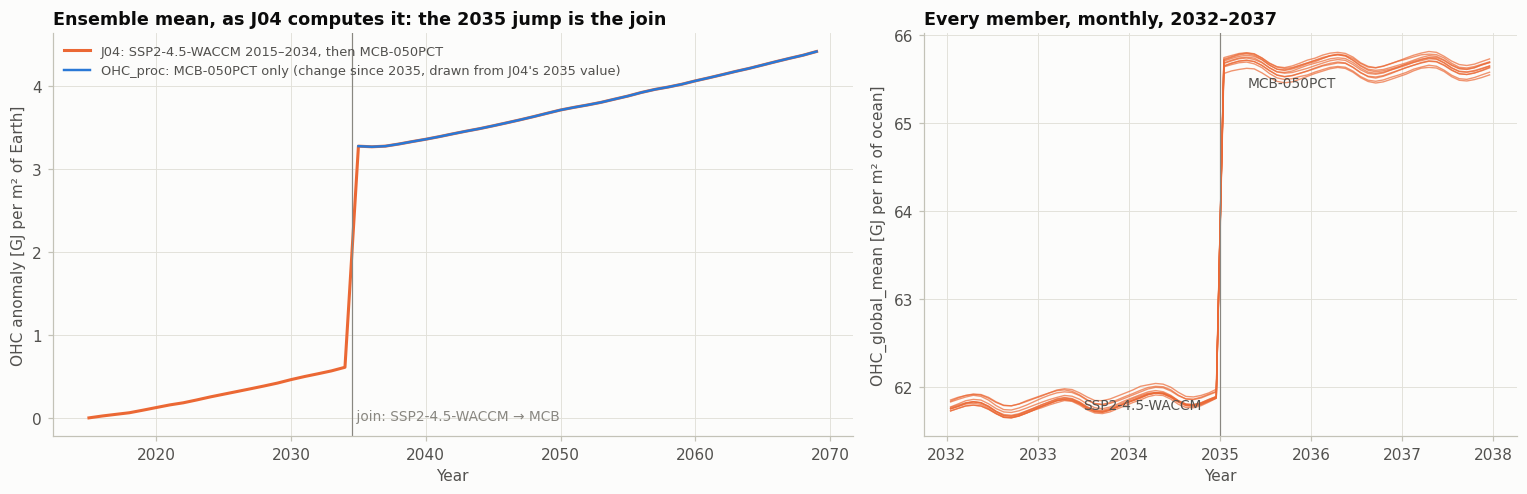

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})

ax = axes[0]
j04_ann = j15.weighted_annualmean(j04_plotted).mean("ens")
ax.plot(j04_ann.year, j04_ann / 1e9, color=J04_COLOR, label="J04: SSP2-4.5-WACCM 2015–2034, then MCB-050PCT")
proc_ann = proc_change.mean("member") / EARTH_SA_CAM  # change since 2035, per m^2 of Earth
start = float(j04_ann.sel(year=2035))
ax.plot(proc_ann.year, (proc_ann + start) / 1e9, color=PROC_COLOR, lw=1.6,
        label="OHC_proc: MCB-050PCT only (change since 2035, drawn from J04's 2035 value)")
ax.axvline(2034.5, color=JOIN_COLOR, lw=0.8)
ax.annotate(" join: SSP2-4.5-WACCM → MCB", xy=(2034.5, 0.04), xycoords=("data", "axes fraction"), color=JOIN_COLOR, fontsize=9)
ax.set(xlabel="Year", ylabel="OHC anomaly [GJ per m² of Earth]",
       title="Ensemble mean, as J04 computes it: the 2035 jump is the join")
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
window = (j04_gm.time.dt.year >= 2032) & (j04_gm.time.dt.year <= 2037)
sub = j04_gm.isel(time=window.values) / 1e3 / MJ  # GJ per m^2 of ocean
t = sub.time.dt.year + (sub.time.dt.month - 0.5) / 12
for m in sub.ens.values:
    ax.plot(t, sub.sel(ens=m), color=J04_COLOR, lw=0.9, alpha=0.7)
ax.axvline(2035, color=JOIN_COLOR, lw=0.8)
ax.set(xlabel="Year", ylabel="OHC_global_mean [GJ per m² of ocean]",
       title="Every member, monthly, 2032–2037")
ax.annotate("SSP2-4.5-WACCM", xy=(2033.5, float(sub.min()) + 0.1), color=oc.INK2, fontsize=9)
ax.annotate("MCB-050PCT", xy=(2035.3, float(sub.max()) - 0.4), color=oc.INK2, fontsize=9)
fig.tight_layout()
plt.show()

## 3. Why the levels don't match

If the jump came from a calculation difference (e.g. a different ρ·c_p constant), the MCB/SSP ratio would be the same
in every depth bin. Below, four products are compared in the same month (January 2035, the first MCB month): member
001 of MCB-050PCT and of CESM2-WACCM SSP2-4.5, the CMIP6-compset MCB baseline
(`b.e21.BSSP245cmip6...CMIP6-baseline.000`) and the CMIP6-compset MCB-050PCT run.

In [7]:
def month_value(pattern, year, month):
    ds = xr.open_mfdataset(sorted(glob.glob(OHC_ROOT + pattern, recursive=True)), use_cftime=True,
                           data_vars="minimal", coords="minimal", compat="override", chunks={})
    sel = (ds.time.dt.year == year) & (ds.time.dt.month == month)
    return ds["OHC_global_mean"].isel(time=np.flatnonzero(sel.values)[0]).load() / MJ

products = {
    "SSP2-4.5-WACCM.001 (J04's prepended parent)": month_value("CESM2_WACCM_SSP2-4.5/*.001/**/*.nc", 2035, 1),
    "MCB-050PCT.001 (smbb)": month_value("CESM2_WACCM_SSP2-4.5_MCB/MCB-050PCT-ensm1/**/*.nc", 2035, 1),
    "CMIP6-baseline.000": month_value("CESM2_WACCM_SSP2-4.5_MCB/Baseline/**/*.nc", 2035, 1),
    "CMIP6-MCB-050PCT.000": month_value("CESM2_WACCM_SSP2-4.5_MCB/CMIP6-MCB-050PCT/**/*.nc", 2035, 1),
}
depth_names = {-1: "full column", 300: "0–300 m", 700: "0–700 m", 2000: "0–2000 m"}
levels = pd.DataFrame({name: v.values for name, v in products.items()},
                      index=[depth_names[int(d)] for d in next(iter(products.values())).ohc_depth.values]).T
levels.columns.name = "Jan 2035 OHC_global_mean [MJ/m² ocean]"
display(levels.style.format("{:,.0f}"))

ratios = pd.DataFrame({
    "MCB-050PCT (smbb) / SSP2-4.5-WACCM": levels.iloc[1] / levels.iloc[0],
    "CMIP6-baseline / SSP2-4.5-WACCM": levels.iloc[2] / levels.iloc[0],
    "CMIP6-MCB-050PCT / CMIP6-baseline": levels.iloc[3] / levels.iloc[2],
    "MCB-050PCT (smbb) / CMIP6-baseline": levels.iloc[1] / levels.iloc[2],
}).T
display(ratios.style.format("{:.4f}"))

Jan 2035 OHC_global_mean [MJ/m² ocean],full column,0–300 m,0–700 m,0–2000 m
SSP2-4.5-WACCM.001 (J04's prepended parent),"61,903","17,186","29,007","46,630"
MCB-050PCT.001 (smbb),"65,566","17,271","29,309","47,828"
CMIP6-baseline.000,"64,676","17,262","29,311","47,676"
CMIP6-MCB-050PCT.000,"64,674","17,261","29,309","47,674"


Jan 2035 OHC_global_mean [MJ/m² ocean],full column,0–300 m,0–700 m,0–2000 m
MCB-050PCT (smbb) / SSP2-4.5-WACCM,1.0592,1.0050,1.0104,1.0257
CMIP6-baseline / SSP2-4.5-WACCM,1.0448,1.0045,1.0105,1.0224
CMIP6-MCB-050PCT / CMIP6-baseline,1.0000,0.9999,0.9999,1.0000
MCB-050PCT (smbb) / CMIP6-baseline,1.0138,1.0005,0.9999,1.0032


## 4. Result

**The 2035 feature in J04 is a splice artifact, not ocean physics, and OHC_proc is right not to show it.**

- Over the MCB run itself (2035–2069) both routes read **identical** monthly OHC for the same 10 members (`.e11` is a
  duplicate of `.011` and is excluded by both). J04's data reproduce OHC_proc's change since 2035 to within 0.07 ZJ
  of ≈ 580 ZJ; that small gap is only J04 weighting months by length in its annual means where OHC_proc takes a plain
  mean of the 12 months.
- The difference is entirely the 2015–2034 segment J04 prepends. Its configuration (`J15_shared_functions`,
  `CASE_CONFIGS_TEMPLATE["CESM2_WACCM_SSP2-4.5_MCB"]["append_cases"]`) attaches **CESM2-WACCM** SSP2-4.5
  (`BWSSP245cmip6`) to the MCB-050PCT runs, but the MCB runs are **CESM2 with CAM6** (`BSSP245smbb`; no `W` in the
  compset), a different model configuration with its own spun-up ocean. At the join every member jumps by +3,690 to
  +3,870 MJ m⁻² of ocean (mean +3,774, i.e. 2.7 × 10⁹ J m⁻² of Earth in J04's units) — about 58× the largest
  month-to-month change and 75× the spread (standard deviation) between members.
  Because J04 plots OHC relative to Jan 2015, that jump stays in every later value; with its centered 10-year
  running mean it appears as a steep rise around 2030–2040.
- The jump is a different ocean state, not a different calculation: the ratio grows with depth (≈ 1.005 in the
  top 300 m, ≈ 1.06 for the full column), so most of the extra heat is in the deep ocean, as expected from a
  different spin-up. All four products carry the same OHC method description and ocean area.
- The CMIP6-compset MCB runs (`BSSP245cmip6 ... CMIP6-MCB-0xxPCT.000`) continue seamlessly from
  `CMIP6-baseline.000` (ratio 1.0000 ± 0.0001 in every bin), so that baseline — not CESM2-WACCM SSP2-4.5 — is their parent.
  The smbb MCB-050PCT members do not continue from either available run (≈ +1.4% vs. the CMIP6 baseline, again
  mostly below 2000 m); their parent (presumably an smbb SSP2-4.5 baseline) is not in `PRISM_data`.

**Suggested fixes for J04** (in `J15_shared_functions.CASE_CONFIGS_TEMPLATE`):
1. Set the MCB-050PCT (smbb) append case to `None`, so its curve starts in 2035 rather than being spliced onto a
   different model.
2. For the CMIP6-compset MCB runs, append `b.e21.BSSP245cmip6.f09_g17.CMIP6-baseline.000` instead of
   CESM2-WACCM SSP2-4.5.
3. Revisit `preceding_case` (the end-of-HIST offset) for MCB as well: it also comes from CESM2-WACCM.

The same splice is applied to J04's atmosphere variables (FSNT, FLNT, TS) for MCB, so similar jumps are likely there
too; this notebook only checks OHC.